In [ ]:
# 1. Import Library
# -----------------------------------
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE

In [ ]:
# 2. Load Dataset
# -----------------------------------
df = pd.read_csv('/content/hasil_preprocessing_pendidikan online.csv')

# Ubah kolom list dari string jadi list Python
for col in ['tokenized', 'no_stopwords', 'stemmed']:
    if col in df.columns:
        df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Gabungkan kata (untuk TF-IDF)
df['text'] = df['stemmed'].apply(lambda x: ' '.join(x) if isinstance(x, list) else '')


In [ ]:
# 1. DAFTAR KATA SENTIMEN (LEKSIKON YANG DIPERLUAS)
kata_positif = [
    'baik', 'bagus', 'hebat', 'positif', 'mantap', 'senang', 'terbaik', 'luar biasa', 'mudah',
    'cepat', 'efisien', 'menyenangkan', 'membantu', 'memudahkan', 'informatif', 'berguna',
    'relevan', 'menarik', 'inovatif', 'update', 'meningkatkan', 'bermanfaat'
]

kata_negatif = [
    'buruk', 'jelek', 'negatif', 'parah', 'benci', 'gagal', 'susah', 'ribet', 'lambat',
    'tidak jelas', 'tidak membantu', 'tidak efektif', 'membingungkan', 'mengecewakan',
    'kacau', 'tidak relevan', 'salah', 'bosan', 'berulang', 'tidak berguna'
]

# 2. FUNGSI PEMBERIAN LABEL DENGAN LEBIH TELITI
def label_sentimen_lebih_lengkap(kalimat):
    if not isinstance(kalimat, list):
        return 'netral'
    positif = sum(any(word in kata for kata in kata_positif) for word in kalimat)
    negatif = sum(any(word in kata for kata in kata_negatif) for word in kalimat)
    if positif > negatif:
        return 'positif'
    elif negatif > positif:
        return 'negatif'
    else:
        return 'netral'

# 3. TERAPKAN FUNGSI KE DATASET
df['label'] = df['stemmed'].apply(label_sentimen_lebih_lengkap)

# 4. TAMPILKAN DISTRIBUSI LABEL BARU
print("Distribusi Label Setelah Leksikon Diperluas:")
print(df['label'].value_counts())

Distribusi Label Setelah Leksikon Diperluas:
label
netral     292
positif    131
negatif     82
Name: count, dtype: int64


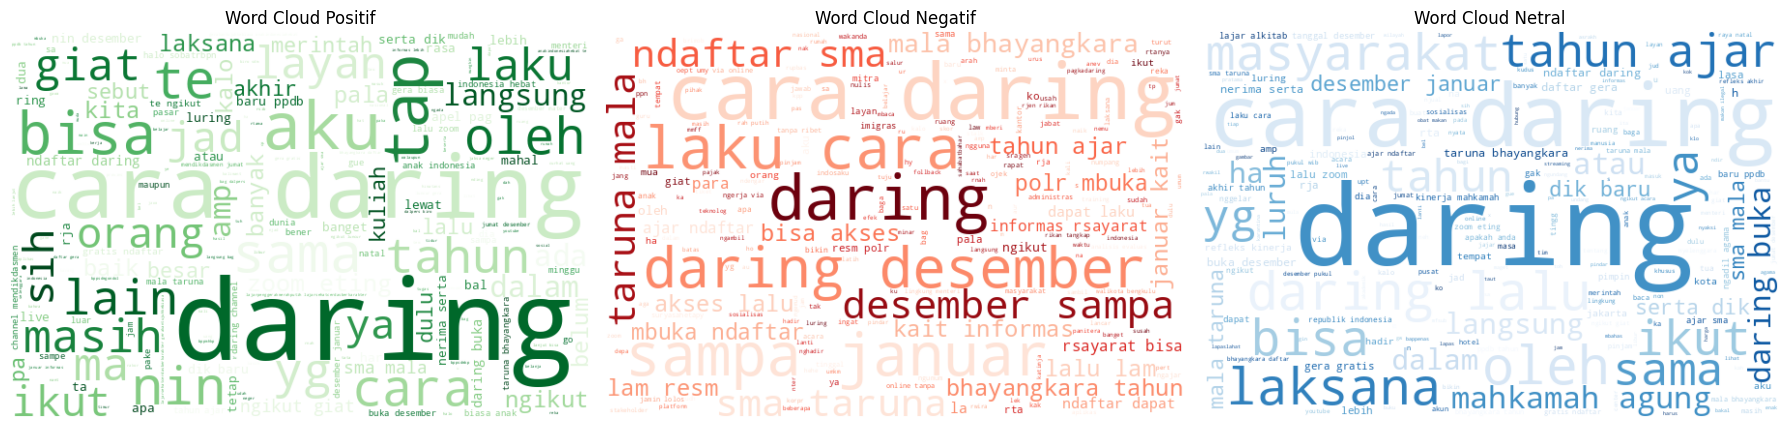

In [ ]:
# 5. Word Cloud per Sentimen
# -----------------------------------
def gabungkan_kata(label):
    return df[df['label'] == label]['stemmed'].dropna().apply(lambda x: ' '.join(x)).str.cat(sep=' ')

text_positif = gabungkan_kata('positif')
text_negatif = gabungkan_kata('negatif')
text_netral = gabungkan_kata('netral')

plt.figure(figsize=(18, 5))

# Positif
plt.subplot(1, 3, 1)
wordcloud_pos = WordCloud(width=600, height=400, background_color='white', colormap='Greens').generate(text_positif)
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud Positif")

# Negatif
plt.subplot(1, 3, 2)
wordcloud_neg = WordCloud(width=600, height=400, background_color='white', colormap='Reds').generate(text_negatif)
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud Negatif")

# Netral
plt.subplot(1, 3, 3)
wordcloud_net = WordCloud(width=600, height=400, background_color='white', colormap='Blues').generate(text_netral)
plt.imshow(wordcloud_net, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud Netral")

plt.tight_layout()
plt.show()

In [ ]:
# 6. TF-IDF dan SMOTE
# -----------------------------------
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['text'])
y = df['label']

# SMOTE balancing
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, stratify=y_resampled, random_state=42
)


In [ ]:
# 7. Naive Bayes Klasifikasi
# -----------------------------------
model = MultinomialNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

Akurasi: 0.8465909090909091

Confusion Matrix:
[[58  0  0]
 [ 7 32 20]
 [ 0  0 59]]

Classification Report:
              precision    recall  f1-score   support

     negatif       0.89      1.00      0.94        58
      netral       1.00      0.54      0.70        59
     positif       0.75      1.00      0.86        59

    accuracy                           0.85       176
   macro avg       0.88      0.85      0.83       176
weighted avg       0.88      0.85      0.83       176



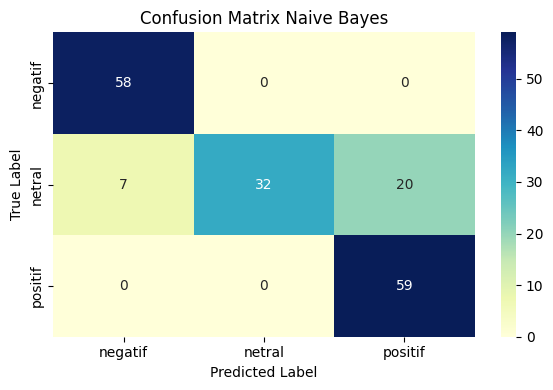

In [ ]:
# 8. Evaluasi Model
# -----------------------------------
print("Akurasi:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix Visual
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d',
            xticklabels=model.classes_, yticklabels=model.classes_, cmap='YlGnBu')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Naive Bayes')
plt.tight_layout()
plt.show()